<a href="https://colab.research.google.com/github/CamilaAg-05/Data_Analytics_3-Camila_Aguado/blob/main/notebooks/S14_ML_Challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 2. PCA

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist


## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)


In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [7]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 1
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 01 | Semilla: 1001
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 9e0cf0664d9d


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [8]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


In [9]:
# Costo de referencia: el Dummy nunca alerta, así que todos los retrasos son falsos negativos (FN).
COSTO_FP, COSTO_FN = 8, 35   # supuesto didáctico del reto (R$ por error)
fn_ref = int(((pred_ref == 0) & (y_valid == 1)).sum())
costo_ref = COSTO_FN * fn_ref
print('FN del Dummy:', fn_ref, '| Costo de referencia: R$', costo_ref)

FN del Dummy: 355 | Costo de referencia: R$ 12425


## 4. Semana 14: PCA


In [10]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.decomposition import PCA
from scipy.stats import ks_2samp

In [11]:

ruta_pca = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler(),
                         PCA(svd_solver='full'))
ruta_pca.fit(X_train[columnas_numericas])

pca_full = ruta_pca[-1]
var_ratio = pca_full.explained_variance_ratio_  # información de cada componente
var_acum = np.cumsum(var_ratio)                 # suma acumulada

# Primer número de componentes que llega a 90 %
n_comp_90 = int(np.argmax(var_acum >= 0.90) + 1)

print('Variables numéricas:', len(columnas_numericas))
print('Componentes para 90 %:', n_comp_90)
print('Varianza real:', round(var_acum[n_comp_90 - 1] * 100, 2), '%')

Variables numéricas: 24
Componentes para 90 %: 15
Varianza real: 90.64 %


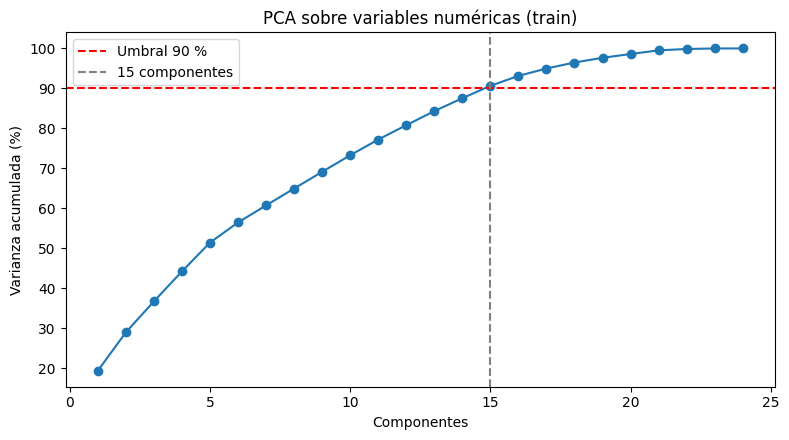

In [12]:
# Información conservada según el número de componentes
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(var_acum) + 1), var_acum * 100, marker='o')
plt.axhline(90, color='red', ls='--', label='Umbral 90 %')
plt.axvline(n_comp_90, color='gray', ls='--', label=f'{n_comp_90} componentes')
plt.xlabel('Componentes'); plt.ylabel('Varianza acumulada (%)')
plt.title('PCA sobre variables numéricas (train)')
plt.legend(); plt.tight_layout(); plt.show()

**Análisis de la curva de varianza.** Las 24 variables numéricas se resumen en 15 componentes, que conservan el 90,64 % de la varianza (reducción de 24 a 15, cerca del 37 %). La curva sube de forma gradual: no hay unas pocas componentes que concentren casi toda la información. Esto indica que las variables numéricas tienen poca redundancia, por lo que comprimirlas implica perder algo de información real.

In [13]:
# Peso de cada variable en CP1 y CP2
cargas = pd.DataFrame(pca_full.components_[:2].T,
                      index=columnas_numericas, columns=['CP1', 'CP2'])
for cp in ['CP1', 'CP2']:
    top = cargas[cp].abs().sort_values(ascending=False).head(5).index
    print(cp, round(var_ratio[int(cp[-1]) - 1] * 100, 1), '%')
    display(cargas.loc[top, cp].round(3))

CP1 19.4 %


,CP1
valor_pagado,0.404
valor_productos,0.387
peso_total_g,0.355
precio_maximo,0.352
volumen_total_cm3,0.335


CP2 9.6 %


,CP2
cantidad_items,0.365
proporcion_flete,0.364
precio_maximo,-0.346
cantidad_productos,0.341
cantidad_vendedores,0.290


**Análisis de las componentes.** La CP1 explica solo el 19,4 % y agrupa variables de tamaño y valor del pedido (`valor_pagado`, `valor_productos`, `peso_total_g`, `precio_maximo`, `volumen_total_cm3`): pedidos grandes y caros. La CP2 explica el 9,6 % y refleja la composición del pedido (`cantidad_items`, `cantidad_productos`, `cantidad_vendedores`, `proporcion_flete`). Juntas suman cerca del 29 %, así que ninguna componente domina.

## 5. Experimentos A-D


Cuatro modelos con la misma muestra, las mismas particiones, `class_weight='balanced'` y umbral 0,50. Solo cambian PCA y C:

| Exp. | Variables numéricas | C |
|---|---|---|
| A | Originales (sin PCA) | 1,0 |
| B | PCA 90 % | 1,0 |
| C | PCA 90 % | 0,1 |
| D | PCA 90 % | 10,0 |


In [14]:
# Arma el modelo: con o sin PCA, y con regularización C
def construir_modelo(usar_pca, C):
    pasos_num = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        pasos_num.append(PCA(n_components=0.90, svd_solver='full'))
    prep = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_num), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas)])
    # balanced: da más peso a los retrasos
    return make_pipeline(prep, LogisticRegression(C=C, class_weight='balanced', max_iter=1000))

resultados = {}  # métricas por experimento
modelos = {}     # modelos entrenados

def ejecutar(nombre, usar_pca, C):
    m = construir_modelo(usar_pca, C)
    m.fit(X_train, y_train)                  # entrena con train
    proba = m.predict_proba(X_valid)[:, 1]   # probabilidad de retraso
    pred = (proba >= 0.50).astype(int)       # umbral fijo 0,50
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()
    resultados[nombre] = {
        'C': C, 'PCA': usar_pca,
        'accuracy': accuracy_score(y_valid, pred),
        'precision': precision_score(y_valid, pred, zero_division=0),
        'recall': recall_score(y_valid, pred),
        'f1': f1_score(y_valid, pred, zero_division=0),
        'ap': average_precision_score(y_valid, proba),
        'FP': int(fp), 'FN': int(fn),
        'costo': COSTO_FP * int(fp) + COSTO_FN * int(fn)}  # 8*FP + 35*FN
    modelos[nombre] = m
    print(nombre, {k: round(v, 4) if isinstance(v, float) else v
                   for k, v in resultados[nombre].items()})

ejecutar('A', usar_pca=False, C=1.0)  # sin PCA (referencia)

A {'C': 1.0, 'PCA': False, 'accuracy': 0.6686, 'precision': 0.121, 'recall': 0.6225, 'f1': 0.2026, 'ap': np.float64(0.16), 'FP': 1606, 'FN': 134, 'costo': 17538}


In [15]:
ejecutar('B', usar_pca=True, C=1.0)   # con PCA

B {'C': 1.0, 'PCA': True, 'accuracy': 0.6396, 'precision': 0.1061, 'recall': 0.5831, 'f1': 0.1795, 'ap': np.float64(0.1264), 'FP': 1744, 'FN': 148, 'costo': 19132}


In [16]:
ejecutar('C', usar_pca=True, C=0.1)   # penalización más fuerte

C {'C': 0.1, 'PCA': True, 'accuracy': 0.6421, 'precision': 0.1068, 'recall': 0.5831, 'f1': 0.1805, 'ap': np.float64(0.1293), 'FP': 1731, 'FN': 148, 'costo': 19028}


In [17]:
ejecutar('D', usar_pca=True, C=10.0)  # penalización más débil

D {'C': 10.0, 'PCA': True, 'accuracy': 0.6377, 'precision': 0.106, 'recall': 0.5859, 'f1': 0.1795, 'ap': np.float64(0.1252), 'FP': 1755, 'FN': 147, 'costo': 19185}


In [18]:
# Componentes que retuvo el PCA en B
pca_modelo = modelos['B'][0].named_transformers_['numericas'][-1]
print('Componentes en B:', pca_modelo.n_components_)

tabla = pd.DataFrame(resultados).T    # una fila por experimento
display(tabla.round(4))

Componentes en B: 15


,C,PCA,accuracy,precision,recall,f1,ap,FP,FN,costo
A,1.0,False,0.668571,0.120963,0.622535,0.202566,0.159967,1606,134,17538
B,1.0,True,0.639619,0.106099,0.583099,0.179532,0.126434,1744,148,19132
C,0.1,True,0.642095,0.106811,0.583099,0.180549,0.129305,1731,148,19028
D,10.0,True,0.637714,0.10596,0.585915,0.179465,0.125231,1755,147,19185


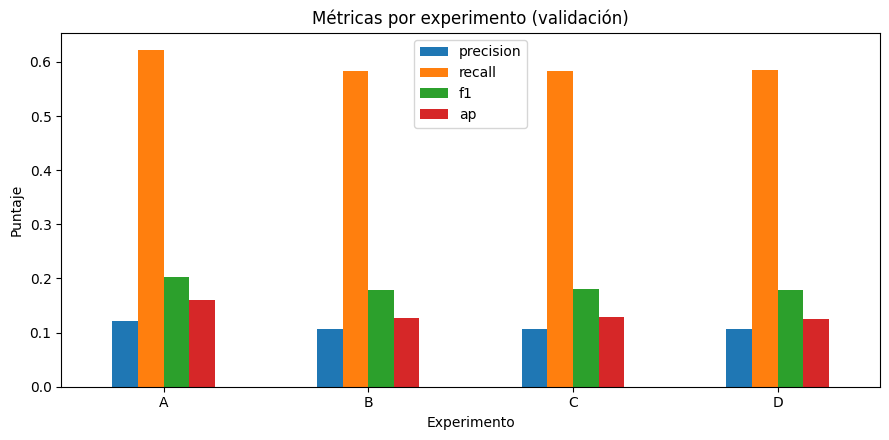

In [19]:
# Compara las métricas de los cuatro experimentos
tabla[['precision', 'recall', 'f1', 'ap']].astype(float).plot(kind='bar', figsize=(9, 4.5))
plt.title('Métricas por experimento (validación)')
plt.ylabel('Puntaje'); plt.xlabel('Experimento'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Análisis de A-D.** Comparado con A (sin PCA), B (PCA 90 %) pierde capacidad en todas las métricas: Recall 0,623 → 0,583, F1 0,203 → 0,180 y AP 0,160 → 0,126. Detecta 207 retrasos en vez de 221. Cambiar la regularización casi no modifica el resultado: C (C=0,1) y D (C=10) quedan prácticamente igual que B (F1 entre 0,179 y 0,181; Recall entre 0,583 y 0,586). Son diferencias de centésimas que no permiten decir que una regularización sea mejor. La conclusión es que en este problema lo que más pesa es usar PCA o no, y no el valor de C.

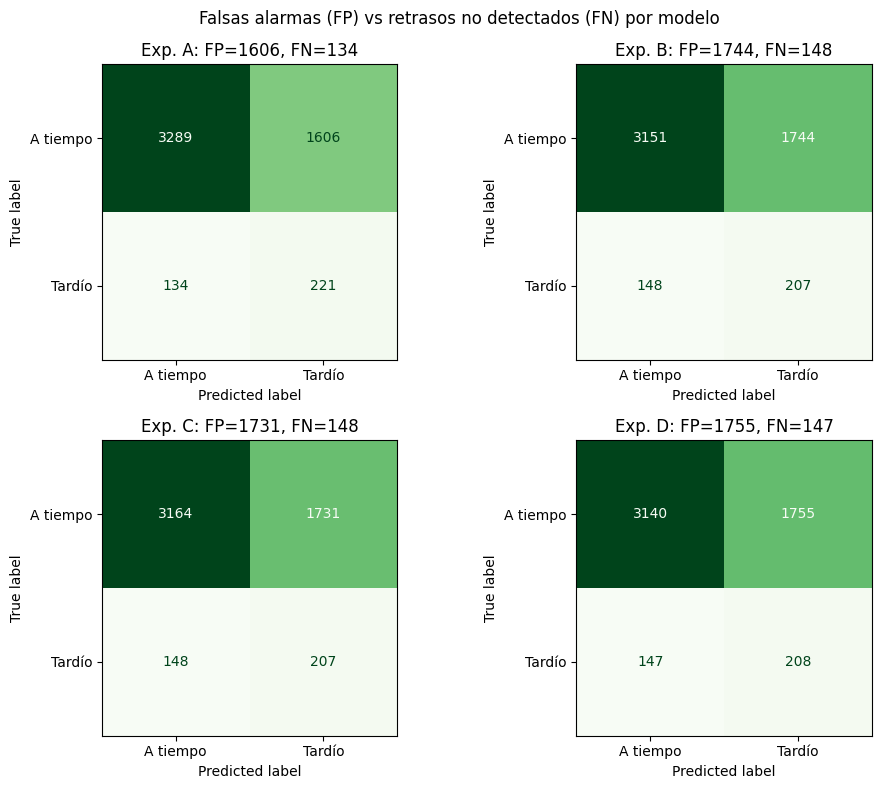

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, nombre in zip(axes.ravel(), ['A', 'B', 'C', 'D']):
    p = (modelos[nombre].predict_proba(X_valid)[:, 1] >= 0.50).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_valid, p, ax=ax, colorbar=False,
                                            display_labels=['A tiempo', 'Tardío'], cmap='Greens')
    ax.set_title(f'Exp. {nombre}: FP={resultados[nombre]["FP"]}, FN={resultados[nombre]["FN"]}')
fig.suptitle('Falsas alarmas (FP) vs retrasos no detectados (FN) por modelo')
plt.tight_layout(); plt.show()

**Análisis: ** En los cuatro modelos casi todo el error son falsas alarmas (FP): entre 1.606 y 1.755 pedidos puntuales marcados como tardíos, frente a solo 134-148 retrasos no detectados (FN). El modelo A es el que comete menos errores de ambos tipos (FP 1.606, FN 134). B, C y D agregan alrededor de 130-150 falsas alarmas y 13-14 retrasos más sin detectar. Hay 355 retrasos reales en validación, así que ningún modelo supera el 63 % de detección.

## 6. Costo



,FP,FN,costo,recall,f1
A,1606.0,134.0,17538.0,0.622535,0.202566
B,1744.0,148.0,19132.0,0.583099,0.179532
C,1731.0,148.0,19028.0,0.583099,0.180549
D,1755.0,147.0,19185.0,0.585915,0.179465
Dummy,0.0,355.0,12425.0,0.000000,0.000000


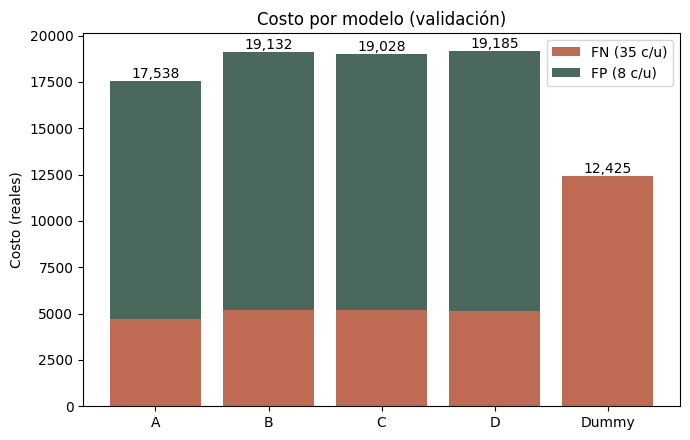

In [21]:
# Se agrega el Dummy (nunca alerta) para comparar
tabla_costo = tabla[['FP', 'FN', 'costo', 'recall', 'f1']].astype(float)
tabla_costo.loc['Dummy'] = [0, fn_ref, costo_ref, 0.0, 0.0]
display(tabla_costo)

# Barras apiladas: costo de FN + costo de FP
c_fp = COSTO_FP * tabla_costo['FP']
c_fn = COSTO_FN * tabla_costo['FN']
plt.figure(figsize=(7, 4.5))
plt.bar(tabla_costo.index, c_fn, color='#bf6a52', label='FN (35 c/u)')
plt.bar(tabla_costo.index, c_fp, bottom=c_fn, color='#4a695c', label='FP (8 c/u)')
for i, n in enumerate(tabla_costo.index):
    plt.text(i, c_fn[n] + c_fp[n], f'{int(c_fn[n] + c_fp[n]):,}', ha='center', va='bottom')
plt.ylabel('Costo (reales)'); plt.title('Costo por modelo (validación)')
plt.legend(); plt.tight_layout(); plt.show()

In [22]:
# Menor costo y mejor F1
elegido = tabla['costo'].astype(float).idxmin()
print('Menor costo:', elegido)
print('Mejor F1:', tabla['f1'].astype(float).idxmax())

Menor costo: A
Mejor F1: A


**Análisis de costo.** El modelo A (sin PCA) es el de menor costo (R\$ 17.538) y el de mejor F1 (0,203). Su costo viene sobre todo de las falsas alarmas: 1.606 × R\$ 8 = R\$ 12.848 (73 %), frente a R\$ 4.690 de retrasos no detectados (134 × R\$ 35). Usar PCA no ayuda: B, C y D cuestan entre R\$ 19.028 y R\$ 19.185, unos R\$ 1.500 más que A.

 entre los evaluados, A es el mejor, pero no lo desplegaría tal cual. Antes habría que reducir las falsas alarmas.

## 7. Prueba de Kolmogorov-Smirnov sobre `valor_flete`


In [23]:
# H0: misma distribución en train y validación. H1: distintas. alfa = 0,05
res_ks = ks_2samp(train['valor_flete'].dropna(), valid['valor_flete'].dropna())

print('D =', round(res_ks.statistic, 4))
print('p =', round(res_ks.pvalue, 4))
print('Tamaños:', train['valor_flete'].notna().sum(), '|', valid['valor_flete'].notna().sum())
print('Decisión:', 'rechazar H0' if res_ks.pvalue < 0.05 else 'no rechazar H0')

D = 0.0131
p = 0.4455
Tamaños: 24500 | 5250
Decisión: no rechazar H0


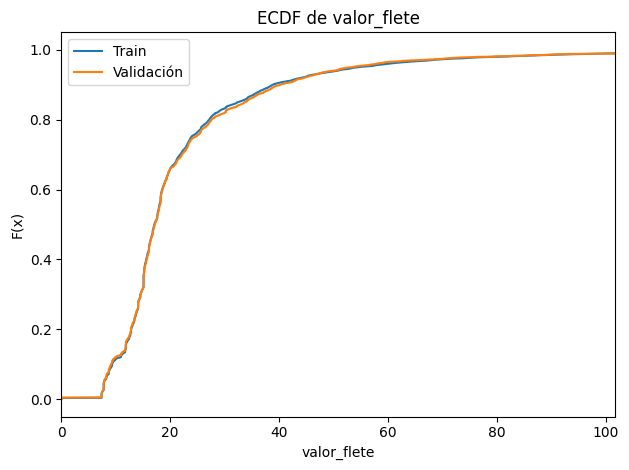

,train,valid
count,24500.00,5250.00
mean,22.71,22.65
std,23.38,19.72
min,0.00,0.00
25%,13.86,13.77
50%,17.09,17.17
75%,23.85,24.46
max,1794.96,371.46


Proporción de valores repetidos en train (empates): 0.812


In [24]:
# ECDF: fracción de pedidos con flete <= x. D = mayor distancia entre curvas
for datos, nombre in [(train['valor_flete'], 'Train'), (valid['valor_flete'], 'Validación')]:
    x = np.sort(datos.dropna().values)
    plt.plot(x, np.arange(1, len(x) + 1) / len(x), label=nombre)
plt.xlim(0, train['valor_flete'].quantile(0.99))  # recorta el 1 % extremo
plt.xlabel('valor_flete'); plt.ylabel('F(x)'); plt.title('ECDF de valor_flete')
plt.legend(); plt.tight_layout(); plt.show()

# Mediana y cuartiles de cada grupo
display(pd.DataFrame({'train': train['valor_flete'].describe(),
                      'valid': valid['valor_flete'].describe()}).round(2))
print('Proporción de valores repetidos en train (empates):', round(train['valor_flete'].duplicated().mean(), 3))

**Análisis.** Las curvas de entrenamiento y validación casi se superponen. La prueba KS da D = 0,0131 y p = 0,4455. como p > 0,05, no se rechaza H0, no hay evidencia de que el flete se distribuya distinto en ambas particiones (media 22,71 vs 22,65 y mediana 17,09 vs 17,17).

## 8. Interpretación




**1. ¿PCA redujo dimensiones y a qué costo?** Sí: pasó de 24 a 15 variables numéricas (90,64 % de varianza). Pero el Recall bajó de 0,623 a 0,583, el F1 de 0,203 a 0,180 y la AP de 0,160 a 0,126; detecta 14 retrasos menos (207 vs 221) y el costo sube R\$ 1.594. Reducir variables sí tuvo un costo en la detección.


**2. Modelo recomendado.** Entre los evaluados, el **experimento A (sin PCA, C = 1)**: tiene el mayor Recall (0,623), F1 (0,203) y AP (0,160) y el menor costo (R\$ 17.538). Una falsa alarma cuesta R\$ 8 y un retraso no detectado R\$ 35 (supuestos didácticos). Sin embargo, el Dummy cuesta R\$ 12.425, menos que A, así que con umbral 0,50 no recomendaría desplegarlo tal cual: generaría demasiadas falsas alarmas (1.606). Antes habría que reducirlas, por ejemplo con otro umbral o con mejores variables.

**3.** Para este problema, **PCA no funciona**, no mejora ninguna métrica y empeora el costo. Reduce variables, pero a cambio de perder detección. La razón es que PCA elige por varianza y no por utilidad para predecir retrasos, y las variables disponibles aportan poca señal.
